# Modern Portfolio Theory: Mathematical Optimization of Risk and Return Using Python

**Project:** Mathematical foundations, 5,000 random portfolios, constrained SciPy optimization, efficient frontier, **training-only sensitivity experiments**, and **chronological out-of-sample evaluation**.

**Research question:** *How can capital allocation among four technology stocks affect return and volatility, and do estimated optimization benefits survive a later held-out sample?*

**Scope:** Fully invested, long-only allocations across AAPL, MSFT, GOOG and AMZN; weekly simple returns; annualized arithmetic moment estimates. The first 70% of weekly returns provide training estimates; the last 30% are held out. Weight choices are not informed by the test period.

**Interpretation:** Results illustrate historical price-index returns under stylized assumptions; they are **not** investment advice or reliable forecasts.

## 1. Objectives and scientific approach

1. Define the allocation problem and its assumptions using the mean–variance model.
2. Validate historical normalized price indices and split weekly returns chronologically.
3. Estimate training-only annualized means, covariance and correlations.
4. Implement and test portfolio arithmetic return and volatility calculations.
5. Simulate 5,000 reproducible long-only portfolio weights.
6. Find minimum variance and maximum Sharpe allocations with SLSQP and construct an efficient frontier.
7. **Experiment A:** assess how the assumed risk-free rate affects the training-optimal maximum Sharpe allocation.
8. **Experiment B:** impose a 50% per-asset concentration cap and quantify its in-sample opportunity cost.
9. **Hold-out evaluation:** freeze the original training-estimated weights and compare their realized weekly-rebalanced wealth, annualized moments and maximum drawdowns with the equal-weight benchmark.
10. Conclude, noting weaknesses, validity threats, and possible follow-up research.

**Hypothesis:** Constrained optimization will improve *estimated in-sample* objective values relative to finite random sampling, but those improvements **need not persist** in held-out data. Sensitivity experiments use training moments only; the held-out period does not guide portfolio selection.

## 2. Data and reproducibility

We use the **Plotly sample stocks dataset** (six technology stocks, 2018–2019). The local CSV is an extracted subset of the four selected companies. The series are *normalized price indices* starting at 1, **not** USD price quotes. Percent changes of a normalized index are suitable for this exercise.

**Source:** [Plotly data documentation](https://plotly.com/python-api-reference/generated/plotly.data.html) — `plotly.data.stocks()` (also available as `plotly.express.data.stocks()`).

**Limitations:** The dataset covers a short and dated interval, consists entirely of technology stocks, and does not document whether the indices include cash dividends, transactions costs, or other real-market frictions. We therefore analyze *sample price-index returns*, not actual total investor returns.

The CSV is included with this repository; rerunning the notebook requires **no internet connection**.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.25})

DATA_PATH = Path("data/stocks_normalized_2018_2019.csv")
ASSETS = ["AAPL", "MSFT", "GOOG", "AMZN"]
WEEKS_PER_YEAR = 52

In [2]:
prices = pd.read_csv(DATA_PATH, parse_dates=["date"]).set_index("date")
prices = prices[ASSETS].sort_index()

# Explicit checks keep the analysis reproducible and fail early on bad data.
assert not prices.empty
assert prices.index.is_unique and prices.index.is_monotonic_increasing
assert not prices.isna().any().any()
assert (prices > 0).all().all()
assert prices.shape[0] >= 100

print(f"Observations: {len(prices)}")
print(f"From: {prices.index.min().date()} to {prices.index.max().date()}")
display(prices.head())

Observations: 105
From: 2018-01-01 to 2019-12-30


,AAPL,MSFT,GOOG,AMZN
date,,,,
2018-01-01,1.000000,1.000000,1.000000,1.000000
2018-01-08,1.011943,1.015988,1.018172,1.061881
2018-01-15,1.019771,1.020524,1.032008,1.053240
2018-01-22,0.980057,1.066561,1.066783,1.140676
2018-01-29,0.917143,1.040708,1.008773,1.163374


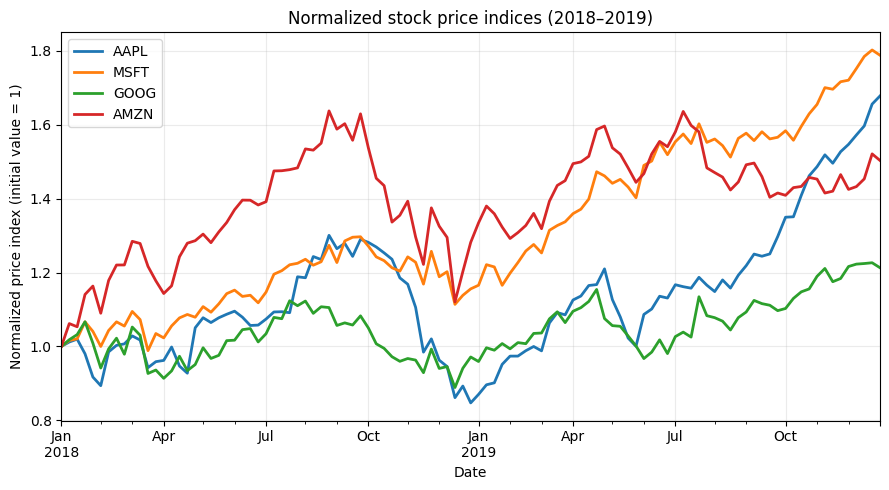

In [3]:
ax = prices.plot(linewidth=2, title="Normalized stock price indices (2018–2019)")
ax.set_ylabel("Normalized price index (initial value = 1)")
ax.set_xlabel("Date")
plt.tight_layout()
plt.show()

## 3. Mathematical background

Let $P_{i,t}$ be the normalized index value for stock $i$ at week $t$. Its **weekly simple return** is

$$r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1.$$

For $n=4$ assets, the portfolio weight vector is $\mathbf{w}=(w_1,\dots,w_4)^T$ with long-only, fully invested constraints

$$\sum_{i=1}^4 w_i=1, \qquad 0\le w_i\le 1.$$

The estimated **annualized arithmetic expected return** and **annualized covariance matrix** are

$$\boldsymbol{\hat\mu}_{ann}=52\,\overline{\mathbf r}_{weekly}, \qquad \hat\Sigma_{ann}=52\,\widehat{\mathrm{Cov}}(\mathbf r_{weekly}).$$

The corresponding estimated portfolio expected return and volatility are

$$\hat\mu_p=\mathbf w^T\boldsymbol{\hat\mu}_{ann}, \qquad
\hat\sigma_p=\sqrt{\mathbf w^T\hat\Sigma_{ann}\mathbf w}.$$

The square-root in the final expression converts **variance** into **standard deviation**. This is the mean-variance portfolio framework discussed by Markowitz (1952). For weekly observations, the factor of 52 is an approximation based on stationarity and standard aggregation assumptions. Annualized arithmetic mean return is **not** the same as realized compounded annual return.

In [4]:
weekly_returns = prices.pct_change().dropna()
assert len(weekly_returns) == len(prices) - 1
assert np.isfinite(weekly_returns.to_numpy()).all()

# Chronological split: reserve the last 30% for later out-of-sample evaluation.
split_at = int(len(weekly_returns) * 0.70)
train_returns = weekly_returns.iloc[:split_at].copy()
test_returns = weekly_returns.iloc[split_at:].copy()
assert train_returns.index.max() < test_returns.index.min()

annual_mean = train_returns.mean() * WEEKS_PER_YEAR
annual_cov = train_returns.cov() * WEEKS_PER_YEAR
annual_volatility = train_returns.std(ddof=1) * np.sqrt(WEEKS_PER_YEAR)

summary = pd.DataFrame({
    "Annualized arithmetic mean": annual_mean,
    "Annualized volatility": annual_volatility,
})
print(f"Training weeks: {len(train_returns)}; held-out weeks: {len(test_returns)}")
display(summary.style.format("{:.2%}"))

Training weeks: 72; held-out weeks: 32


,Annualized arithmetic mean,Annualized volatility
AAPL,6.05%,30.03%
MSFT,28.15%,21.00%
GOOG,5.10%,24.89%
AMZN,33.22%,30.72%


## 4. Diversification and covariance

Diversification is not solely about the number of assets; it depends on how their returns co-move. Correlation near +1 implies limited diversification benefit, while lower correlations can reduce portfolio variance for a fixed set of weights. These four technology companies are not a broad representation of the market.

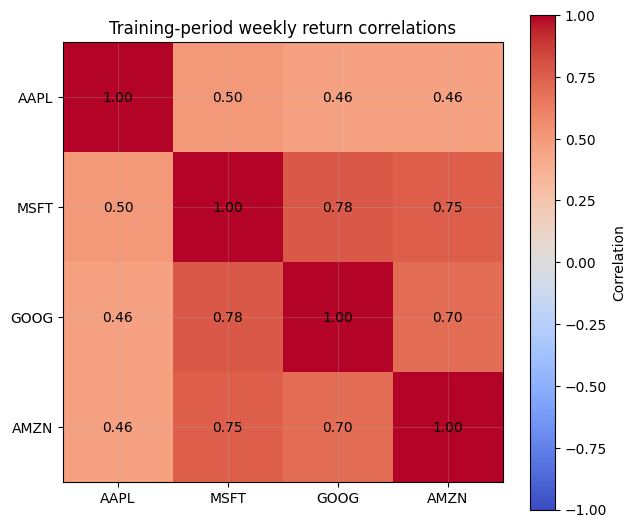

In [5]:
correlation = train_returns.corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(correlation.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(ASSETS)), ASSETS)
ax.set_yticks(range(len(ASSETS)), ASSETS)
for i in range(len(ASSETS)):
    for j in range(len(ASSETS)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Training-period weekly return correlations")
fig.tight_layout()
plt.show()

## 5. Equal-weight benchmark and validation

A neutral baseline assigns 25% to each of the four assets. It is **not** necessarily the lowest-risk or highest-return allocation. Implementing the formulas from Section 3 provides a testable benchmark for later numerical optimization.

In [6]:
def portfolio_statistics(weights: np.ndarray,
                         expected_returns: pd.Series,
                         covariance: pd.DataFrame) -> tuple[float, float]:
    """Return annualized arithmetic expected return and volatility.

    Parameters
    ----------
    weights : array of shape (n_assets,)
        Non-negative portfolio fractions summing to one.
    expected_returns : Series
        Estimated annualized arithmetic asset returns.
    covariance : DataFrame
        Estimated annualized asset return covariance matrix.
    """
    w = np.asarray(weights, dtype=float)
    mu = expected_returns.to_numpy(dtype=float)
    sigma = covariance.to_numpy(dtype=float)
    if w.ndim != 1 or w.size != len(mu) or sigma.shape != (w.size, w.size):
        raise ValueError("Incompatible vector or covariance dimensions")
    if not np.isclose(w.sum(), 1.0, atol=1e-8) or np.any(w < -1e-10):
        raise ValueError("Weights must be non-negative and sum to 1")

    expected_return = float(w @ mu)
    variance = float(w @ sigma @ w)
    volatility = float(np.sqrt(max(variance, 0.0)))  # protect against rounding
    return expected_return, volatility


weights_equal = np.full(len(ASSETS), 1 / len(ASSETS))
equal_return, equal_volatility = portfolio_statistics(weights_equal, annual_mean, annual_cov)
print("Equal-weight allocation:", dict(zip(ASSETS, weights_equal)))
print(f"Estimated annualized arithmetic return: {equal_return:.2%}")
print(f"Estimated annualized volatility:       {equal_volatility:.2%}")

Equal-weight allocation: {'AAPL': np.float64(0.25), 'MSFT': np.float64(0.25), 'GOOG': np.float64(0.25), 'AMZN': np.float64(0.25)}
Estimated annualized arithmetic return: 18.13%
Estimated annualized volatility:       22.25%


In [7]:
# Mathematical checks: a 100% allocation to one asset must reproduce
# that asset's expected return and volatility.
for i, asset in enumerate(ASSETS):
    single_asset_weights = np.eye(len(ASSETS))[i]
    r, v = portfolio_statistics(single_asset_weights, annual_mean, annual_cov)
    assert np.isclose(r, annual_mean[asset], rtol=1e-10)
    assert np.isclose(v, annual_volatility[asset], rtol=1e-10)

assert np.allclose(annual_cov, annual_cov.T)
assert np.linalg.eigvalsh(annual_cov.to_numpy()).min() > -1e-10
print("All portfolio formula checks passed.")

All portfolio formula checks passed.


## 6. Monte Carlo simulation of 5,000 feasible portfolios

### Motivation and mathematical method

Instead of choosing portfolio weights arbitrarily, we sample many feasible allocations and evaluate each under the same historical estimates of mean return and covariance. This is a **Monte Carlo search over weights**, not a simulation of future stock prices or portfolio outcomes.

For every sampled portfolio $k$, we calculate

$$\widehat\mu_p^{(k)} = (\mathbf w^{(k)})^T \widehat{\boldsymbol\mu}_{ann},$$

$$\widehat\sigma_p^{(k)} = \sqrt{(\mathbf w^{(k)})^T\widehat\Sigma_{ann}\mathbf w^{(k)}}.$$

We draw $\mathbf w^{(k)} \sim \mathrm{Dirichlet}(1,1,1,1)$. This distribution yields nonnegative components summing to one and is uniform with respect to volume on the four-asset weight simplex. It does **not** guarantee that the best sampled point is a true mathematical optimum.

For comparative visualization, define an *illustrative* assumed risk-free annual rate $r_f=2\%$, and compute the estimated Sharpe ratio

$$\widehat S_p^{(k)} = \frac{\widehat\mu_p^{(k)} - r_f}{\widehat\sigma_p^{(k)}}.$$

The 2% rate is a **modeling assumption** used consistently in the comparison, not a historically verified risk-free yield. Arithmetic sample mean, sample covariance, and volatility remain fixed for all candidate portfolios, estimated **only from training observations**.

In [8]:
# Reproducible random search (sampling portfolio weights, NOT future prices).
N_PORTFOLIOS = 5_000
RANDOM_SEED = 42
ASSUMED_RISK_FREE_RATE = 0.02  # annualized, hypothetical

rng = np.random.default_rng(RANDOM_SEED)
random_weights = rng.dirichlet(np.ones(len(ASSETS)), size=N_PORTFOLIOS)

# All simulated portfolios satisfy the long-only, fully invested constraints.
assert random_weights.shape == (N_PORTFOLIOS, len(ASSETS))
assert np.all(random_weights >= 0.0)
assert np.allclose(random_weights.sum(axis=1), 1.0, atol=1e-12)
assert np.allclose(
    random_weights[:3],
    np.random.default_rng(RANDOM_SEED).dirichlet(np.ones(len(ASSETS)), size=3),
)

mean_vector = annual_mean.to_numpy(dtype=float)
covariance_matrix = annual_cov.to_numpy(dtype=float)

# Vectorized versions of w.T @ mu and sqrt(w.T @ Sigma @ w).
simulated_returns = random_weights @ mean_vector
simulated_variances = np.einsum(
    "ij,jk,ik->i", random_weights, covariance_matrix, random_weights
)
simulated_volatilities = np.sqrt(np.maximum(simulated_variances, 0.0))
assert np.all(simulated_volatilities > 0)
simulated_sharpe = (
    simulated_returns - ASSUMED_RISK_FREE_RATE
) / simulated_volatilities

# Verify the vectorized computation against the earlier single-portfolio function.
for i in range(10):
    r, v = portfolio_statistics(random_weights[i], annual_mean, annual_cov)
    assert np.isclose(simulated_returns[i], r, rtol=1e-12)
    assert np.isclose(simulated_volatilities[i], v, rtol=1e-12)

simulated = pd.DataFrame(random_weights, columns=[f"weight_{a}" for a in ASSETS])
simulated["expected_return"] = simulated_returns
simulated["volatility"] = simulated_volatilities
simulated["sharpe"] = simulated_sharpe

print(f"Generated and validated {len(simulated):,} feasible portfolios.")
display(simulated.head().round(4))

Generated and validated 5,000 feasible portfolios.


,weight_AAPL,weight_MSFT,weight_GOOG,weight_AMZN,expected_return,volatility,sharpe
0,0.3247,0.3155,0.3220,0.0378,0.1374,0.2142,0.5482
1,0.0142,0.2392,0.2322,0.5144,0.2510,0.2472,0.9343
2,0.0347,0.4580,0.0308,0.4765,0.2909,0.2393,1.1321
3,0.4942,0.1104,0.3515,0.0439,0.0935,0.2300,0.3195
4,0.0532,0.1831,0.5237,0.2400,0.1612,0.2307,0.6122


### Representative portfolios from the simulation

We identify two *best observed among the 5,000 random candidates*:

- **Lowest sampled volatility:** the candidate with minimum $\widehat\sigma_p$.
- **Highest sampled Sharpe ratio:** the candidate with maximum $\widehat S_p$.

We compare both against the fixed **25%-per-asset equal-weight portfolio**. None of these estimates represents a guaranteed future performance. In particular, random search is not yet a formal constrained optimizer.

In [9]:
index_min_vol = int(np.argmin(simulated_volatilities))
index_max_sharpe = int(np.argmax(simulated_sharpe))

def candidate_summary(label: str, weights: np.ndarray) -> dict:
    expected_return, volatility = portfolio_statistics(weights, annual_mean, annual_cov)
    result = {
        "Portfolio": label,
        "Expected return": expected_return,
        "Volatility": volatility,
        "Sharpe (rf=2%)": (expected_return - ASSUMED_RISK_FREE_RATE) / volatility,
    }
    result.update({f"{asset} weight": weight for asset, weight in zip(ASSETS, weights)})
    return result

candidate_weights = {
    "Equal weight": weights_equal,
    "Lowest sampled volatility": random_weights[index_min_vol],
    "Highest sampled Sharpe": random_weights[index_max_sharpe],
}
comparison = pd.DataFrame(
    [candidate_summary(name, weights) for name, weights in candidate_weights.items()]
).set_index("Portfolio")

# Display percentages and a dimensionless Sharpe ratio separately.
formatters = {name: "{:.2%}" for name in comparison.columns if name != "Sharpe (rf=2%)"}
formatters["Sharpe (rf=2%)"] = "{:.3f}"
display(comparison.style.format(formatters))

print("For this fixed random seed and training dataset:")
for name in ["Lowest sampled volatility", "Highest sampled Sharpe"]:
    row = comparison.loc[name]
    print(f"{name}: return = {row['Expected return']:.2%}, "
          f"volatility = {row['Volatility']:.2%}, Sharpe = {row['Sharpe (rf=2%)']:.3f}")

assert comparison.loc["Lowest sampled volatility", "Volatility"] <= comparison.loc["Equal weight", "Volatility"]
assert comparison.loc["Highest sampled Sharpe", "Sharpe (rf=2%)"] >= comparison.loc["Equal weight", "Sharpe (rf=2%)"]

,Expected return,Volatility,Sharpe (rf=2%),AAPL weight,MSFT weight,GOOG weight,AMZN weight
Portfolio,,,,,,,
Equal weight,18.13%,22.25%,0.725,25.00%,25.00%,25.00%,25.00%
Lowest sampled volatility,21.27%,20.45%,0.943,14.69%,69.23%,15.81%,0.27%
Highest sampled Sharpe,28.42%,21.30%,1.240,0.12%,88.63%,0.98%,10.27%


For this fixed random seed and training dataset:
Lowest sampled volatility: return = 21.27%, volatility = 20.45%, Sharpe = 0.943
Highest sampled Sharpe: return = 28.42%, volatility = 21.30%, Sharpe = 1.240


### Visualizing the risk–return trade-off

Each point below is one random feasible portfolio, positioned using **training-period estimates**. Color represents its estimated Sharpe ratio under the hypothetical 2% annual risk-free assumption. The **simulation cloud is not the analytical efficient frontier**; we will compute constrained optima in the next part.

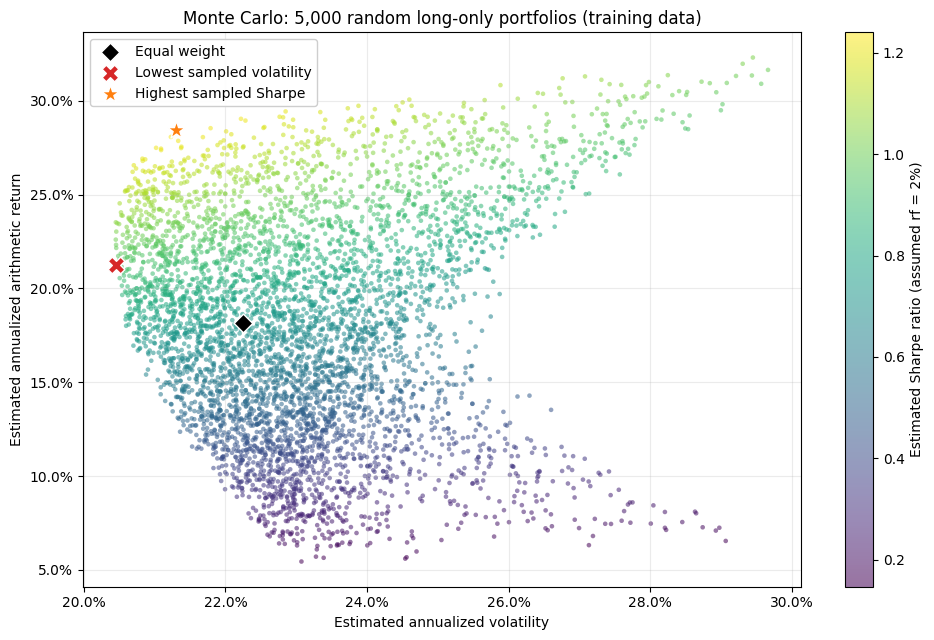

Saved plot: figures/monte_carlo_risk_return.png


In [10]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(10, 6.5))
scatter = ax.scatter(
    simulated_volatilities, simulated_returns,
    c=simulated_sharpe, cmap="viridis", s=11, alpha=0.55,
    linewidths=0, rasterized=True
)

markers = [
    ("Equal weight", "D", "black", 90),
    ("Lowest sampled volatility", "X", "tab:red", 145),
    ("Highest sampled Sharpe", "*", "tab:orange", 180),
]
for label, marker, color, size in markers:
    point = comparison.loc[label]
    ax.scatter(
        point["Volatility"], point["Expected return"],
        marker=marker, s=size, facecolor=color, edgecolor="white",
        linewidth=1.0, label=label, zorder=5
    )

ax.set_title("Monte Carlo: 5,000 random long-only portfolios (training data)")
ax.set_xlabel("Estimated annualized volatility")
ax.set_ylabel("Estimated annualized arithmetic return")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(loc="best", framealpha=0.95)
fig.colorbar(scatter, ax=ax, label="Estimated Sharpe ratio (assumed rf = 2%)")
fig.tight_layout()

# A local figure is convenient for including in README or a report.
from pathlib import Path
figure_path = Path("figures/monte_carlo_risk_return.png")
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved plot: {figure_path}")

## 7. Monte Carlo: interpretation and limitations

- Sampling 5,000 valid, fully invested, long-only weight vectors reveals a wide range of estimated risk–return combinations using one historical training dataset.
- The **lowest sampled volatility** and **highest sampled Sharpe** are best *only within that finite random draw*. Neither is guaranteed to solve the underlying constrained optimization problem.
- All sampled portfolios use exactly the same estimated annualized moments, so the comparison is internally consistent but subject to estimation error.
- Since four highly correlated technology stocks form the investable universe, diversification is constrained and results should not be generalized to a diversified market portfolio.
- The chronological held-out sample remains untouched during selection and optimization.

## 8. Constrained numerical portfolio optimization (SciPy SLSQP)

### Model and constraints

Let $\hat{\boldsymbol\mu}$ and $\hat\Sigma$ denote **training-sample estimates** of annualized arithmetic returns and covariance. We solve two constrained problems on the same feasible set:

$$\mathcal{W}=\{\mathbf{w}:\sum_{i=1}^4 w_i=1,\ 0\le w_i\le1\}.$$

**Global minimum variance (GMV)** seeks the smallest estimated variance:

$$\min_{\mathbf w\in\mathcal W}\quad \mathbf w^T\hat\Sigma\mathbf w.$$

This is a convex quadratic program because the sample covariance matrix is positive semidefinite. Minimizing *variance* and *volatility* gives the same minimizer.

**Maximum Sharpe ratio** maximizes the estimated excess return per unit volatility:

$$\max_{\mathbf w\in\mathcal W}\quad
\frac{\mathbf w^T\hat{\boldsymbol\mu}-r_f}{\sqrt{\mathbf w^T\hat\Sigma\mathbf w}},\qquad r_f=0.02.$$

We minimize the *negative* Sharpe ratio in `scipy.optimize.minimize(method="SLSQP")`. SLSQP supports bounds and equality constraints. While the GMV problem is convex, SLSQP's success status alone is **not** a mathematical proof of global optimality for the Sharpe objective. We therefore also verify feasibility and compare results from several initial guesses. The risk-free rate is an **illustrative assumption**, not an observed market yield.

In [11]:
from scipy.optimize import minimize

BOUNDS = [(0.0, 1.0)] * len(ASSETS)
EQUALITY_CONSTRAINTS = [{
    "type": "eq",
    "fun": lambda weights: float(np.sum(weights) - 1.0),
    "jac": lambda weights: np.ones_like(weights),
}]
SOLVER_OPTIONS = {"ftol": 1e-12, "maxiter": 2000, "disp": False}


def estimated_variance(weights: np.ndarray) -> float:
    """Annualized variance, evaluated from training estimates only."""
    w = np.asarray(weights, dtype=float)
    return float(w @ covariance_matrix @ w)


def variance_gradient(weights: np.ndarray) -> np.ndarray:
    """Gradient: ∇(wᵀΣw) = 2Σw (for symmetric Σ)."""
    return 2.0 * (covariance_matrix @ np.asarray(weights, dtype=float))


def negative_sharpe(weights: np.ndarray) -> float:
    """Negative estimated Sharpe ratio for scalar minimization."""
    w = np.asarray(weights, dtype=float)
    volatility = np.sqrt(estimated_variance(w))
    return -float((w @ mean_vector - ASSUMED_RISK_FREE_RATE) / volatility)


def negative_sharpe_gradient(weights: np.ndarray) -> np.ndarray:
    """Analytical gradient of negative Sharpe ratio."""
    w = np.asarray(weights, dtype=float)
    volatility = np.sqrt(estimated_variance(w))
    excess_return = float(w @ mean_vector - ASSUMED_RISK_FREE_RATE)
    return -(mean_vector / volatility - excess_return * (covariance_matrix @ w) / volatility**3)


def checked_solution(solution, label: str) -> np.ndarray:
    """Reject solver failures or infeasible weights instead of masking them."""
    if not solution.success:
        raise RuntimeError(f"{label} did not converge: {solution.message}")
    w = np.asarray(solution.x, dtype=float)
    if not (np.all(w >= -1e-8) and np.all(w <= 1.0 + 1e-8)
            and abs(w.sum() - 1.0) <= 1e-8):
        raise RuntimeError(f"{label} returned infeasible weights: {w}")
    return w

# Independent finite-difference check of the two analytic gradients.
for func, gradient in [(estimated_variance, variance_gradient),
                       (negative_sharpe, negative_sharpe_gradient)]:
    eps = 1e-6
    numerical = np.array([
        (func(weights_equal + eps * np.eye(len(ASSETS))[i])
         - func(weights_equal - eps * np.eye(len(ASSETS))[i])) / (2 * eps)
        for i in range(len(ASSETS))
    ])
    assert np.allclose(gradient(weights_equal), numerical, atol=1e-7)

min_var_result = minimize(
    estimated_variance, x0=weights_equal, jac=variance_gradient,
    method="SLSQP", bounds=BOUNDS, constraints=EQUALITY_CONSTRAINTS,
    options=SOLVER_OPTIONS,
)
max_sharpe_result = minimize(
    negative_sharpe, x0=weights_equal, jac=negative_sharpe_gradient,
    method="SLSQP", bounds=BOUNDS, constraints=EQUALITY_CONSTRAINTS,
    options=SOLVER_OPTIONS,
)

weights_min_var = checked_solution(min_var_result, "Minimum variance")
weights_max_sharpe = checked_solution(max_sharpe_result, "Maximum Sharpe")

# A convex minimum-variance program can be checked from several starts.
# A multi-start consistency check also strengthens confidence in the Sharpe solution.
starting_points = [weights_equal, *np.eye(len(ASSETS)),
                   random_weights[index_min_vol], random_weights[index_max_sharpe]]
for start in starting_points:
    check_min = minimize(
        estimated_variance, start, method="SLSQP", jac=variance_gradient,
        bounds=BOUNDS, constraints=EQUALITY_CONSTRAINTS, options=SOLVER_OPTIONS,
    )
    check_max = minimize(
        negative_sharpe, start, method="SLSQP", jac=negative_sharpe_gradient,
        bounds=BOUNDS, constraints=EQUALITY_CONSTRAINTS, options=SOLVER_OPTIONS,
    )
    check_min_weights = checked_solution(check_min, "Minimum variance multistart")
    check_max_weights = checked_solution(check_max, "Maximum Sharpe multistart")
    assert np.isclose(estimated_variance(check_min_weights), estimated_variance(weights_min_var), atol=1e-8)
    assert np.isclose(negative_sharpe(check_max_weights), negative_sharpe(weights_max_sharpe), atol=1e-7)

print("SLSQP converged for both optimization objectives.")
print(f"Minimum variance:  {min_var_result.nit} iterations; variance {min_var_result.fun:.6f}")
print(f"Maximum Sharpe:    {max_sharpe_result.nit} iterations; Sharpe {-max_sharpe_result.fun:.4f}")
print(f"Repeated from {len(starting_points)} starts; feasibility and gradient checks passed.")

SLSQP converged for both optimization objectives.
Minimum variance:  12 iterations; variance 0.041687
Maximum Sharpe:    8 iterations; Sharpe 1.2511
Repeated from 7 starts; feasibility and gradient checks passed.


### Comparing optimized portfolios to the random search

The optimizer and Monte Carlo candidates use *identical* assumptions, estimates, and constraints. The optimized GMV volatility should be no larger than the minimum observed among random candidates. Similarly, the optimized Sharpe ratio should be at least as high as the maximum sampled Sharpe, up to numerical tolerances. The magnitudes of the differences indicate how much the finite random search missed, **not** how much future portfolio performance improves.

In [12]:
optimized_weights = {
    **candidate_weights,
    "Optimized min variance": weights_min_var,
    "Optimized max Sharpe": weights_max_sharpe,
}
optimized_comparison = pd.DataFrame([
    candidate_summary(name, weights) for name, weights in optimized_weights.items()
]).set_index("Portfolio")

# The optimized solutions should weakly dominate the best of the sampled candidates
# for their own objectives (not necessarily both objectives simultaneously).
assert optimized_comparison.loc["Optimized min variance", "Volatility"] <= (
    optimized_comparison.loc["Lowest sampled volatility", "Volatility"] + 1e-7
)
assert optimized_comparison.loc["Optimized max Sharpe", "Sharpe (rf=2%)"] >= (
    optimized_comparison.loc["Highest sampled Sharpe", "Sharpe (rf=2%)"] - 1e-7
)

percent_columns = [c for c in optimized_comparison.columns if c != "Sharpe (rf=2%)"]
output_format = {col: "{:.2%}" for col in percent_columns}
output_format["Sharpe (rf=2%)"] = "{:.3f}"
display(optimized_comparison.style.format(output_format))

Path("results").mkdir(exist_ok=True)
optimized_comparison.to_csv("results/optimized_portfolio_comparison.csv", float_format="%.10f")

print("\nOptimized allocations:")
for label in ("Optimized min variance", "Optimized max Sharpe"):
    print(label)
    for asset in ASSETS:
        print(f"  {asset}: {optimized_comparison.loc[label, f'{asset} weight']:.2%}")

print("\nImprovements over best sampled portfolios:")
vol_improvement = (
    optimized_comparison.loc["Lowest sampled volatility", "Volatility"]
    - optimized_comparison.loc["Optimized min variance", "Volatility"]
)
sharpe_improvement = (
    optimized_comparison.loc["Optimized max Sharpe", "Sharpe (rf=2%)"]
    - optimized_comparison.loc["Highest sampled Sharpe", "Sharpe (rf=2%)"]
)
print(f"Volatility reduction: {100 * vol_improvement:.4f} percentage points")
print(f"Sharpe increase:       {sharpe_improvement:.4f}")

,Expected return,Volatility,Sharpe (rf=2%),AAPL weight,MSFT weight,GOOG weight,AMZN weight
Portfolio,,,,,,,
Equal weight,18.13%,22.25%,0.725,25.00%,25.00%,25.00%,25.00%
Lowest sampled volatility,21.27%,20.45%,0.943,14.69%,69.23%,15.81%,0.27%
Highest sampled Sharpe,28.42%,21.30%,1.240,0.12%,88.63%,0.98%,10.27%
Optimized min variance,22.20%,20.42%,0.989,16.58%,73.48%,9.94%,0.00%
Optimized max Sharpe,28.65%,21.30%,1.251,0.00%,90.15%,0.00%,9.85%



Optimized allocations:
Optimized min variance
  AAPL: 16.58%
  MSFT: 73.48%
  GOOG: 9.94%
  AMZN: 0.00%
Optimized max Sharpe
  AAPL: 0.00%
  MSFT: 90.15%
  GOOG: 0.00%
  AMZN: 9.85%

Improvements over best sampled portfolios:
Volatility reduction: 0.0327 percentage points
Sharpe increase:       0.0108


## 9. Constructing the numerical efficient frontier

A portfolio is **mean–variance efficient** if, among portfolios with at least its expected return, none has lower estimated volatility. We approximate the upper efficient frontier by solving a sequence of variance-minimization problems with **fixed target return**:

$$\min_{\mathbf w\in\mathcal W}\quad \mathbf w^T\hat\Sigma\mathbf w
\quad\text{subject to}\quad \mathbf w^T\hat{\boldsymbol\mu}=\mu_{\mathrm{target}}.$$

We search target returns from the return of the global minimum-variance portfolio to the largest individual estimated expected return. For each target, we check that both the weight and return constraints hold. This creates a **numerical approximation** of the efficient frontier rather than an analytic closed-form solution.

In [13]:
gmv_return, gmv_vol = portfolio_statistics(weights_min_var, annual_mean, annual_cov)
max_mean_idx = int(np.argmax(mean_vector))
high_return_asset = np.eye(len(ASSETS))[max_mean_idx]
TARGET_COUNT = 45
frontier_targets = np.linspace(gmv_return, mean_vector[max_mean_idx], TARGET_COUNT)
frontier_weights = []
frontier_volatilities = []

for target in frontier_targets:
    # A convex combination of two feasible portfolios is itself feasible and
    # meets the target return; this provides a numerically reliable starting point.
    mix = float((target - gmv_return) / (mean_vector[max_mean_idx] - gmv_return))
    initial_weights = (1.0 - mix) * weights_min_var + mix * high_return_asset

    target_constraints = [
        *EQUALITY_CONSTRAINTS,
        {
            "type": "eq",
            "fun": lambda w, target=target: float(w @ mean_vector - target),
            "jac": lambda w: mean_vector,
        },
    ]
    solution = minimize(
        estimated_variance, x0=initial_weights, jac=variance_gradient,
        method="SLSQP", bounds=BOUNDS, constraints=target_constraints,
        options=SOLVER_OPTIONS,
    )
    w = checked_solution(solution, f"Frontier target={target:.6f}")
    assert abs(w @ mean_vector - target) < 1e-7
    frontier_weights.append(w)
    frontier_volatilities.append(np.sqrt(estimated_variance(w)))

frontier_volatilities = np.asarray(frontier_volatilities)
frontier_weights = np.asarray(frontier_weights)
assert np.isclose(frontier_volatilities[0], gmv_vol, atol=1e-7)
assert np.all(np.diff(frontier_volatilities) >= -1e-6), "Frontier volatility should be nondecreasing on efficient branch"
print(f"Computed {TARGET_COUNT} feasible target-return optimization points.")
print(f"Efficient frontier: min volatility {frontier_volatilities[0]:.2%}, "
      f"highest target return {frontier_targets[-1]:.2%}")

Computed 45 feasible target-return optimization points.
Efficient frontier: min volatility 20.42%, highest target return 33.22%


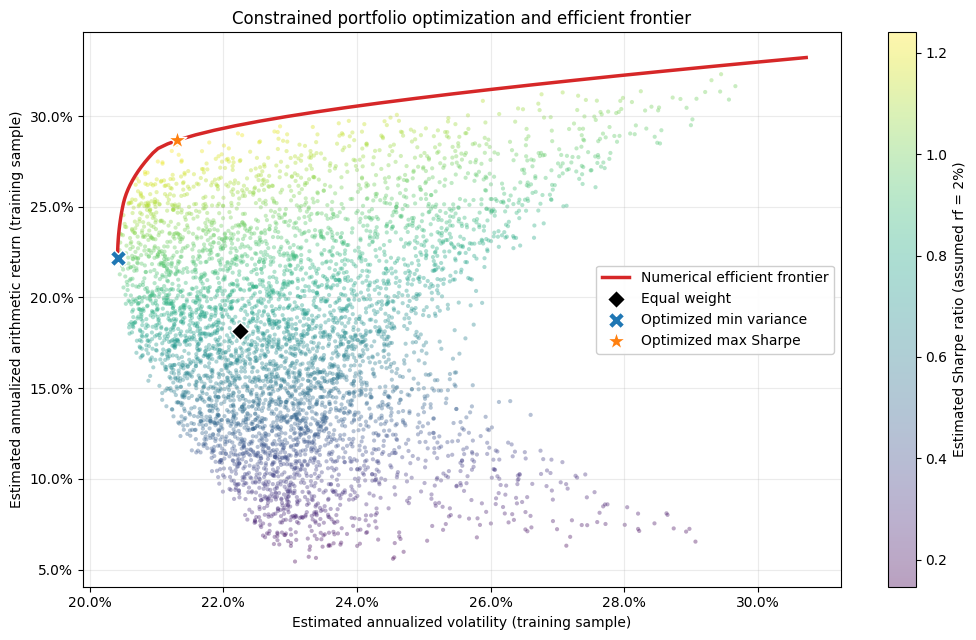

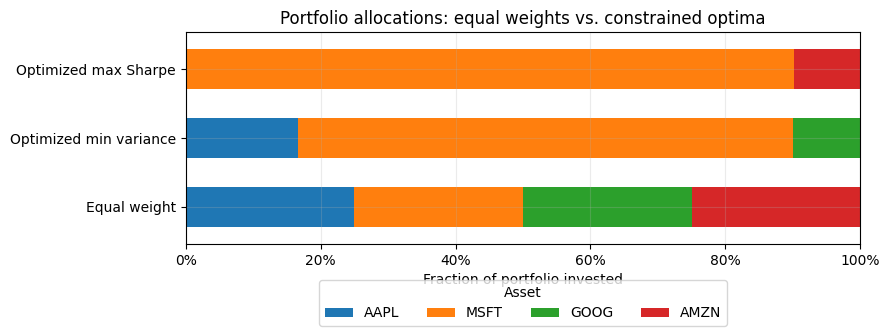

Saved figures: figures/efficient_frontier.png and figures/optimized_allocations.png


In [14]:
# Scatter of Monte Carlo portfolios + numerical efficient frontier + key models.
fig, ax = plt.subplots(figsize=(10.5, 6.5))
sc = ax.scatter(
    simulated_volatilities, simulated_returns, c=simulated_sharpe,
    s=9, alpha=0.37, cmap="viridis", linewidths=0, rasterized=True,
)
ax.plot(
    frontier_volatilities, frontier_targets, c="tab:red", linewidth=2.5,
    label="Numerical efficient frontier", zorder=7,
)

special = [
    ("Equal weight", "D", "black", 85),
    ("Optimized min variance", "X", "tab:blue", 140),
    ("Optimized max Sharpe", "*", "tab:orange", 200),
]
for name, marker, color, size in special:
    row = optimized_comparison.loc[name]
    ax.scatter(
        row["Volatility"], row["Expected return"], marker=marker,
        s=size, c=color, edgecolors="white", linewidths=1.0,
        label=name, zorder=10,
    )
ax.set_xlabel("Estimated annualized volatility (training sample)")
ax.set_ylabel("Estimated annualized arithmetic return (training sample)")
ax.set_title("Constrained portfolio optimization and efficient frontier")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(framealpha=0.95, loc="best")
fig.colorbar(sc, ax=ax, label="Estimated Sharpe ratio (assumed rf = 2%)")
fig.tight_layout()
frontier_figure_path = Path("figures/efficient_frontier.png")
fig.savefig(frontier_figure_path, dpi=160, bbox_inches="tight")
plt.show()

# Compare the allocation patterns directly (weights sum to 100% in each row).
plot_weights = optimized_comparison.loc[
    ["Equal weight", "Optimized min variance", "Optimized max Sharpe"],
    [f"{asset} weight" for asset in ASSETS],
].copy()
plot_weights.columns = ASSETS
assert np.allclose(plot_weights.sum(axis=1), 1.0)
ax = plot_weights.plot.barh(stacked=True, figsize=(9, 3.8), width=0.58)
ax.set_xlabel("Fraction of portfolio invested")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Portfolio allocations: equal weights vs. constrained optima")
ax.legend(title="Asset", loc="lower center", bbox_to_anchor=(0.5, -0.42), ncol=4)
plt.tight_layout()
allocation_figure_path = Path("figures/optimized_allocations.png")
plt.savefig(allocation_figure_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved figures:", frontier_figure_path, "and", allocation_figure_path)

## 10. Interim interpretation: training-sample optimization

1. The global minimum-variance (GMV) solution minimizes variance on the long-only simplex because the estimated covariance is positive semidefinite; our numerical result is feasible and improves on the best randomly sampled volatility.
2. The maximum-Sharpe solution improves estimated Sharpe relative to sampled portfolios for the assumed 2% risk-free rate. Multi-start agreement checks numerical stability but is **not a universal certificate** of global optimality.
3. The optimizer sometimes sets weights to zero. These four stocks belong to one sector, so allocations may be extremely concentrated even without leverage or short selling.
4. The efficient frontier and all results thus far describe **training estimates**, not ex post profits. Arithmetic mean estimates are highly sensitive to short samples.

We now perform **two training-only sensitivity experiments**, then evaluate the original, frozen portfolios once on the held-out weeks. No parameters are chosen on the basis of hold-out performance.

## 11. Sensitivity experiment A: assumed risk-free rate

The estimated maximum-Sharpe objective depends on the assumed annual risk-free rate:

$$S(\mathbf w;r_f)=\frac{\mathbf w^T\hat{\boldsymbol\mu}-r_f}{\sqrt{\mathbf w^T\hat\Sigma\mathbf w}}.$$

We repeat the *training-only* Sharpe optimization for $r_f\in\{0\%,2\%,5\%\}$. All other estimates and constraints remain unchanged. The 2% baseline corresponds to Section 8. These rates are **hypothetical scenarios** and not historically observed bond yields. A change in optimal weights indicates **model sensitivity**, not a recommendation to change investments.

In [15]:
def solve_max_sharpe_for_rate(risk_free_rate: float, *, bounds=BOUNDS,
                              initial_weights=weights_equal) -> np.ndarray:
    """Maximize training-estimated Sharpe under the supplied weight bounds."""
    def objective(w):
        volatility = np.sqrt(estimated_variance(w))
        return -float((w @ mean_vector - risk_free_rate) / volatility)

    def gradient(w):
        volatility = np.sqrt(estimated_variance(w))
        excess = float(w @ mean_vector - risk_free_rate)
        return -(mean_vector / volatility - excess * (covariance_matrix @ w) / volatility**3)

    solution = minimize(
        objective, x0=np.asarray(initial_weights, dtype=float), jac=gradient,
        method="SLSQP", bounds=bounds, constraints=EQUALITY_CONSTRAINTS,
        options=SOLVER_OPTIONS,
    )
    w = checked_solution(solution, f"Sharpe sensitivity (rf={risk_free_rate:.0%})")
    assert all(lo - 1e-8 <= wi <= hi + 1e-8
               for wi, (lo, hi) in zip(w, bounds)), "Box constraints violated"
    return w

RISK_FREE_SCENARIOS = [0.00, 0.02, 0.05]
rf_records = []
for rate in RISK_FREE_SCENARIOS:
    w = solve_max_sharpe_for_rate(rate)
    estimated_return, estimated_vol = portfolio_statistics(w, annual_mean, annual_cov)
    rf_records.append({
        "Assumed risk-free rate": rate,
        "Expected return": estimated_return,
        "Volatility": estimated_vol,
        "Sharpe under scenario": (estimated_return - rate) / estimated_vol,
        "Largest asset weight": max(w),
        **{f"{asset} weight": wi for asset, wi in zip(ASSETS, w)},
    })

rf_sensitivity = pd.DataFrame(rf_records).set_index("Assumed risk-free rate")
rf_format = {c: "{:.2%}" for c in rf_sensitivity.columns if c != "Sharpe under scenario"}
rf_format["Sharpe under scenario"] = "{:.3f}"
display(rf_sensitivity.style.format(rf_format))
rf_sensitivity.to_csv("results/risk_free_rate_sensitivity.csv", float_format="%.10f")

# Re-estimation with identical assumptions must reproduce the Part 3 weights.
assert np.allclose(
    solve_max_sharpe_for_rate(ASSUMED_RISK_FREE_RATE), weights_max_sharpe, atol=1e-6
)
print("Largest change in allocations versus 2% baseline (L1 distance):")
for rate in (0.00, 0.05):
    w_scenario = rf_sensitivity.loc[rate, [f"{a} weight" for a in ASSETS]].to_numpy(dtype=float)
    print(f"  rf={rate:.0%}: {np.abs(w_scenario - weights_max_sharpe).sum():.2%}")

,Expected return,Volatility,Sharpe under scenario,Largest asset weight,AAPL weight,MSFT weight,GOOG weight,AMZN weight
Assumed risk-free rate,,,,,,,,
0.000000,28.58%,21.24%,1.345,91.67%,0.00%,91.67%,0.00%,8.33%
0.020000,28.65%,21.30%,1.251,90.15%,0.00%,90.15%,0.00%,9.85%
0.050000,28.79%,21.42%,1.111,87.36%,0.00%,87.36%,0.00%,12.64%


Largest change in allocations versus 2% baseline (L1 distance):
  rf=0%: 3.04%
  rf=5%: 5.57%


## 12. Sensitivity experiment B: single-asset concentration cap

Without additional diversification constraints, the Sharpe solution may place most capital in one company. We examine the **opportunity cost of a concentration cap** by limiting each asset to 50% of portfolio capital:

$$0\le w_i\le 0.50,\qquad\sum_i w_i=1.$$

We solve both objectives again using only training means and covariances, and compare the constrained results with their original unrestricted (0–100% per stock) counterparts. Because the feasible region is smaller, a 50% cap cannot improve the *best feasible training minimum variance* or *best feasible training Sharpe* relative to an optimum over the original region (subject to numerical error). The cap limits individual-stock concentration but does **not** guarantee market-wide diversification.

,Expected return,Volatility,Sharpe (rf=2%),Max weight,AAPL weight,MSFT weight,GOOG weight,AMZN weight
Model,,,,,,,,
Original min variance,22.20%,20.42%,0.989,73.48%,16.58%,73.48%,9.94%,0.00%
50% cap min variance,16.83%,20.69%,0.717,50.00%,21.84%,50.00%,28.16%,0.00%
Original max Sharpe,28.65%,21.30%,1.251,90.15%,0.00%,90.15%,0.00%,9.85%
50% cap max Sharpe,30.69%,24.28%,1.182,50.00%,0.00%,50.00%,0.00%,50.00%


Cost of 50% cap for the model's respective training objective:
  GMV volatility increase: 0.278 percentage points
  Sharpe decrease: 0.0695


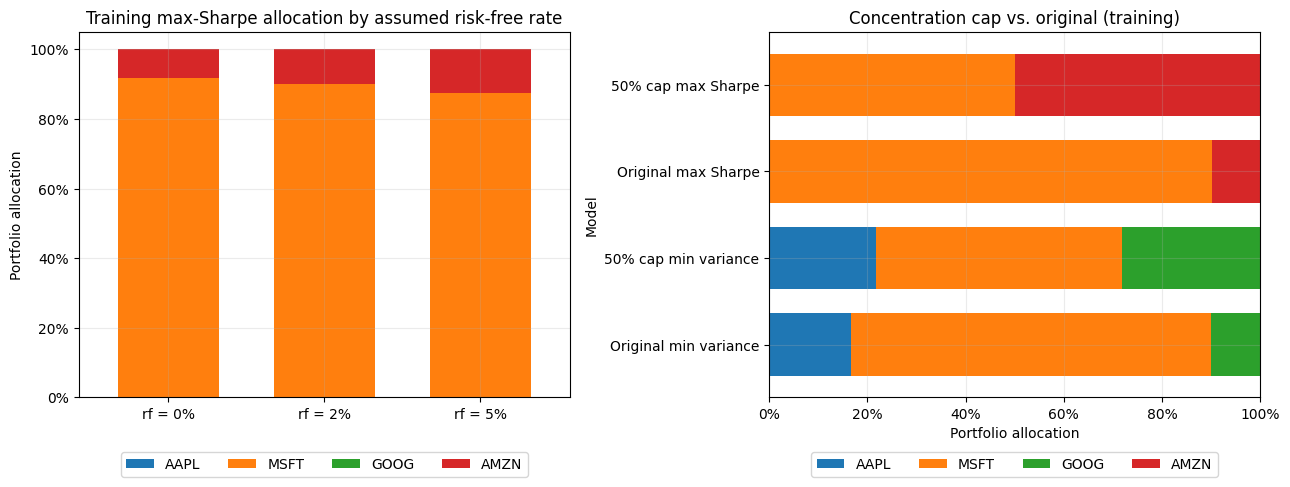

In [16]:
CAP = 0.50
CAPPED_BOUNDS = [(0.0, CAP)] * len(ASSETS)

capped_gmv_solution = minimize(
    estimated_variance, x0=weights_equal, jac=variance_gradient,
    method="SLSQP", bounds=CAPPED_BOUNDS, constraints=EQUALITY_CONSTRAINTS,
    options=SOLVER_OPTIONS,
)
weights_capped_min_var = checked_solution(capped_gmv_solution, "Capped minimum variance")
weights_capped_max_sharpe = solve_max_sharpe_for_rate(
    ASSUMED_RISK_FREE_RATE, bounds=CAPPED_BOUNDS
)
assert max(weights_capped_min_var) <= CAP + 1e-8
assert max(weights_capped_max_sharpe) <= CAP + 1e-8

cap_allocations = {
    "Original min variance": weights_min_var,
    "50% cap min variance": weights_capped_min_var,
    "Original max Sharpe": weights_max_sharpe,
    "50% cap max Sharpe": weights_capped_max_sharpe,
}
cap_rows = []
for label, w in cap_allocations.items():
    r, v = portfolio_statistics(w, annual_mean, annual_cov)
    cap_rows.append({
        "Model": label, "Expected return": r, "Volatility": v,
        "Sharpe (rf=2%)": (r - ASSUMED_RISK_FREE_RATE) / v,
        "Max weight": float(max(w)),
        **{f"{asset} weight": wi for asset, wi in zip(ASSETS, w)},
    })
cap_comparison = pd.DataFrame(cap_rows).set_index("Model")
assert cap_comparison.loc["50% cap min variance", "Volatility"] >= (
    cap_comparison.loc["Original min variance", "Volatility"] - 1e-7
)
assert cap_comparison.loc["50% cap max Sharpe", "Sharpe (rf=2%)"] <= (
    cap_comparison.loc["Original max Sharpe", "Sharpe (rf=2%)"] + 1e-7
)
cap_format = {c: "{:.2%}" for c in cap_comparison.columns if c != "Sharpe (rf=2%)"}
cap_format["Sharpe (rf=2%)"] = "{:.3f}"
display(cap_comparison.style.format(cap_format))
cap_comparison.to_csv("results/concentration_cap_sensitivity.csv", float_format="%.10f")

print("Cost of 50% cap for the model's respective training objective:")
print("  GMV volatility increase:",
      f"{100*(cap_comparison.loc['50% cap min variance', 'Volatility'] - cap_comparison.loc['Original min variance', 'Volatility']):.3f} percentage points")
print("  Sharpe decrease:",
      f"{cap_comparison.loc['Original max Sharpe', 'Sharpe (rf=2%)'] - cap_comparison.loc['50% cap max Sharpe', 'Sharpe (rf=2%)']:.4f}")

# Both scenario families are computed from training quantities only.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rf_sensitivity[[f"{a} weight" for a in ASSETS]].set_axis(
    [f"rf = {r:.0%}" for r in rf_sensitivity.index]
).plot(kind="bar", stacked=True, width=0.65, ax=axes[0], legend=False)
axes[0].set_title("Training max-Sharpe allocation by assumed risk-free rate")
axes[0].set_xlabel("")
axes[0].set_ylabel("Portfolio allocation")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].tick_params(axis="x", rotation=0)

cap_comparison[[f"{a} weight" for a in ASSETS]].set_axis(ASSETS, axis=1).plot(
    kind="barh", stacked=True, width=0.72, ax=axes[1]
)
axes[1].set_title("Concentration cap vs. original (training)")
axes[1].set_xlabel("Portfolio allocation")
axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.13))
axes[0].legend(ASSETS, loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.13))
fig.tight_layout()
fig.savefig("figures/sensitivity_allocations.png", dpi=160, bbox_inches="tight")
plt.show()

## 13. Chronological held-out evaluation (out of sample)

### Protocol: freeze weights before viewing test outcomes

We now evaluate **only three pre-selected portfolios**: equal weight, original training GMV and original training maximum Sharpe ($r_f=2\%$). None of the sensitivity scenarios in Sections 11–12 was selected or tuned using test returns. The final 30% of weekly observations is used for evaluation, not for estimating optimization inputs.

For each frozen weight vector $\mathbf w$, we model a *frictionless weekly rebalanced* portfolio, resetting the portfolio to the same weights at each weekly boundary. Its weekly simple return is

$$r_{p,t}=\sum_{i=1}^{4}w_i r_{i,t}.$$

Starting from $V_0=1$, cumulative wealth is $V_t=\prod_{s=1}^{t}(1+r_{p,s})$. Weekly rebalancing is **not** the same as a buy-and-hold portfolio where weights drift with asset prices. Rebalancing costs, fees and taxes are excluded.

For transparency, we summarize each portfolio using (1) annualized arithmetic sample mean $52\bar r_p$, (2) annualized sample volatility $\sqrt{52}\,s_p$, (3) illustrative annualized Sharpe ratio $(52\bar r_p-0.02)/(\sqrt{52}\,s_p)$, (4) the **realized cumulative return over the held-out interval** $V_T-1$ (not annualized), and (5) maximum observed drawdown $\min_t(V_t/\max_{0\le s\le t}V_s-1)$. Sharpe computed from a short sample is highly uncertain.

In [17]:
# Freeze exactly the solutions optimized without test observations.
FROZEN_PORTFOLIOS = {
    "Equal weight": weights_equal.copy(),
    "Optimized min variance": weights_min_var.copy(),
    "Optimized max Sharpe": weights_max_sharpe.copy(),
}
assert train_returns.index.max() < test_returns.index.min()
assert all(np.isclose(w.sum(), 1.0) and np.all(w >= -1e-8)
           for w in FROZEN_PORTFOLIOS.values())

# Each weekly return assumes the original weights are restored at the start of
# every week; this deliberately excludes any rebalancing transaction costs.
test_portfolios = pd.DataFrame({
    label: test_returns[ASSETS].to_numpy() @ w
    for label, w in FROZEN_PORTFOLIOS.items()
}, index=test_returns.index)
wealth = (1.0 + test_portfolios).cumprod()
wealth_with_initial = pd.concat([
    pd.DataFrame({label: [1.0] for label in FROZEN_PORTFOLIOS},
                 index=[train_returns.index.max()]),
    wealth,
]).sort_index()
assert len(test_portfolios) == len(test_returns)
assert np.isfinite(test_portfolios.to_numpy()).all()
assert (test_portfolios > -1).all().all(), "Invalid return for compounded wealth"
assert np.allclose(wealth.iloc[-1].to_numpy(),
                   np.prod(1 + test_portfolios.to_numpy(), axis=0))

# Benchmark mathematical identity: equally weighted portfolio return equals
# the arithmetic mean of the same four weekly asset returns.
assert np.allclose(test_portfolios["Equal weight"].to_numpy(),
                   test_returns[ASSETS].mean(axis=1).to_numpy())

heldout_rows = []
for label, w in FROZEN_PORTFOLIOS.items():
    weekly = test_portfolios[label]
    wealth_series = wealth_with_initial[label]
    annualized_arithmetic = float(WEEKS_PER_YEAR * weekly.mean())
    annualized_vol = float(np.sqrt(WEEKS_PER_YEAR) * weekly.std(ddof=1))
    max_drawdown = float((wealth_series / wealth_series.cummax() - 1.0).min())
    heldout_rows.append({
        "Portfolio": label,
        "Annualized arithmetic return": annualized_arithmetic,
        "Annualized volatility": annualized_vol,
        "Sharpe (rf=2%)": (annualized_arithmetic - ASSUMED_RISK_FREE_RATE) / annualized_vol,
        "Held-out cumulative return": float(wealth_series.iloc[-1] - 1.0),
        "Max drawdown": max_drawdown,
        "Positive weeks": float((weekly > 0).mean()),
    })

heldout_comparison = pd.DataFrame(heldout_rows).set_index("Portfolio")
assert heldout_comparison.notna().all().all()
heldout_format = {col: "{:.2%}" for col in heldout_comparison.columns
                  if col != "Sharpe (rf=2%)"}
heldout_format["Sharpe (rf=2%)"] = "{:.3f}"
print("Training period:", train_returns.index.min().date(), "to", train_returns.index.max().date(),
      f"({len(train_returns)} weeks)")
print("Held-out period:", test_returns.index.min().date(), "to", test_returns.index.max().date(),
      f"({len(test_returns)} weeks)")
display(heldout_comparison.style.format(heldout_format))
heldout_comparison.to_csv("results/heldout_portfolio_comparison.csv", float_format="%.10f")
wealth_with_initial.to_csv("results/heldout_wealth_paths.csv", float_format="%.10f", index_label="date")

Training period: 2018-01-08 to 2019-05-20 (72 weeks)
Held-out period: 2019-05-27 to 2019-12-30 (32 weeks)


,Annualized arithmetic return,Annualized volatility,Sharpe (rf=2%),Held-out cumulative return,Max drawdown,Positive weeks
Portfolio,,,,,,
Equal weight,38.12%,13.41%,2.694,25.66%,-6.50%,65.62%
Optimized min variance,43.99%,14.17%,2.964,30.17%,-5.32%,65.62%
Optimized max Sharpe,34.04%,14.39%,2.227,22.47%,-6.06%,62.50%


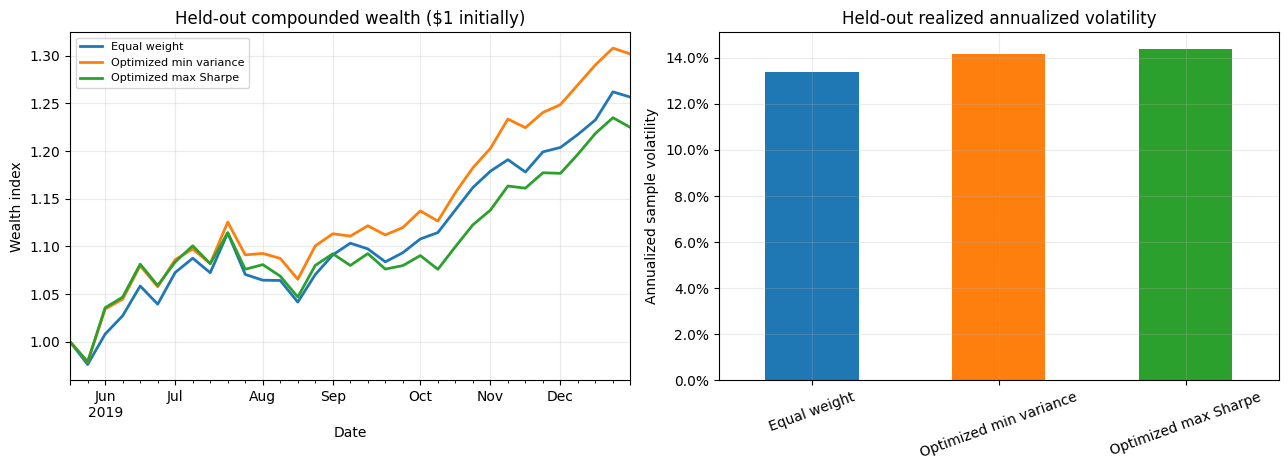

,Training estimated return,Training estimated volatility,Held-out realized return,Held-out realized volatility
Portfolio,,,,
Equal weight,18.13%,22.25%,38.12%,13.41%
Optimized min variance,22.20%,20.42%,43.99%,14.17%
Optimized max Sharpe,28.65%,21.30%,34.04%,14.39%


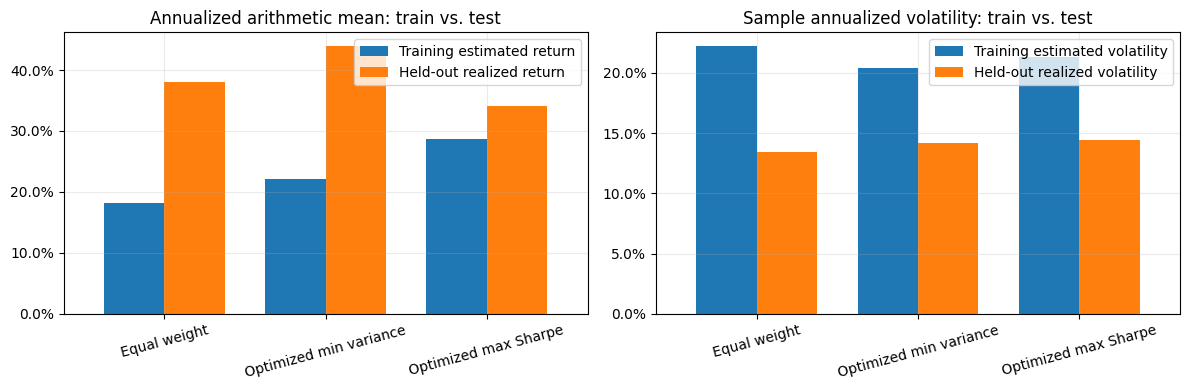

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
wealth_with_initial.plot(ax=axes[0], linewidth=2)
axes[0].set_title("Held-out compounded wealth ($1 initially)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Wealth index")
axes[0].legend(fontsize=8, loc="best")

heldout_comparison["Annualized volatility"].plot.bar(
    ax=axes[1], color=["tab:blue", "tab:orange", "tab:green"]
)
axes[1].set_title("Held-out realized annualized volatility")
axes[1].set_xlabel("")
axes[1].set_ylabel("Annualized sample volatility")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig("figures/heldout_performance.png", dpi=160, bbox_inches="tight")
plt.show()

# Training prediction versus held-out realization (both arithmetic/annualized).
train_vs_test = optimized_comparison.loc[
    list(FROZEN_PORTFOLIOS), ["Expected return", "Volatility"]
].rename(columns={"Expected return": "Training estimated return",
                  "Volatility": "Training estimated volatility"})
train_vs_test["Held-out realized return"] = heldout_comparison["Annualized arithmetic return"]
train_vs_test["Held-out realized volatility"] = heldout_comparison["Annualized volatility"]
display(train_vs_test.style.format("{:.2%}"))
train_vs_test.to_csv("results/train_vs_heldout_comparison.csv", float_format="%.10f")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
train_vs_test[["Training estimated return", "Held-out realized return"]].plot(
    kind="bar", ax=axes[0], width=0.75
)
axes[0].set_title("Annualized arithmetic mean: train vs. test")
axes[0].set_xlabel("")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].tick_params(axis="x", rotation=15)
train_vs_test[["Training estimated volatility", "Held-out realized volatility"]].plot(
    kind="bar", ax=axes[1], width=0.75
)
axes[1].set_title("Sample annualized volatility: train vs. test")
axes[1].set_xlabel("")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig("figures/train_vs_heldout.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Discussion and final conclusion

### Evidence from the sensitivity experiments (training data only)

1. **Risk-free rate dependence:** Raising the hypothetical annual risk-free rate from 0% to 5% shifted the training maximum-Sharpe portfolio's Microsoft weight from **91.67%** to **87.36%** (from 90.15% at the 2% baseline). Thus, even with identical returns and covariance, the optimized allocation depends on a non-estimated modeling assumption.
2. **Effect of a concentration cap:** Capping each asset at 50% limited stock-level exposure, compared with a 73.48% Microsoft weight for the original GMV portfolio and a 90.15% Microsoft weight for the original maximum-Sharpe portfolio. Under the cap, the estimated GMV volatility rose by **0.278 percentage points**, while the optimal estimated Sharpe ratio decreased by **0.0695**. This is the observable *in-sample cost* of restricting the feasible set for these objectives.

### Evidence from the chronological held-out test

We froze the three **original** portfolio allocations before examining the 32 held-out weekly returns (**27 May – 30 December 2019**). We modeled cost-free **weekly rebalancing** to the fixed weights, starting each strategy with a wealth index of 1. The following cumulative returns represent the **32-week test period**, *not* annualized returns:

| Portfolio | Test-period cumulative return | Test annualized volatility | Test Sharpe (assumed 2% rf) | Maximum drawdown |
|:--|--:|--:|--:|--:|
| Equal weight | 25.66% | 13.41% | 2.694 | -6.50% |
| Training GMV | **30.17%** | 14.17% | **2.964** | -5.32% |
| Training max Sharpe | 22.47% | 14.39% | 2.227 | -6.06% |

The GMV allocation achieved a **4.52 percentage-point higher** test-period cumulative return than equal weight. However, it **did not deliver the lowest test-period volatility**: equal weight had 13.41% versus the GMV's 14.17%, even though the training-estimated GMV volatility had been lower (20.42% versus 22.25%). The maximum-Sharpe allocation **underperformed** equal weight by **3.19 percentage points** of cumulative test return and had a lower realized Sharpe ratio. These differences are sample outcomes, **not** statistically established persistent advantages or disadvantages.

Notably, the same asset universe produced markedly different estimated arithmetic annual means between training and held-out periods. Annualizing a short 32-week sample can magnify this apparent variation. These results support the methodological warning: **in-sample mathematical optimality does not guarantee improved out-of-sample results.**

### Limitations and threats to validity

1. **Sampling risk:** Only 72 weekly observations are used for parameter estimation, followed by 32 held-out observations. Annualized arithmetic returns and Sharpe ratios over either sample have large sampling uncertainty.
2. **Sector concentration:** All four assets are US technology companies. Stock-level weight constraints do not ensure broad asset-class diversification.
3. **Data interpretation:** The input is a Plotly sample of normalized *price indices*. Inclusion of dividends and corporate-action treatment is unverified, so the results are not investor total returns.
4. **Trading model:** Rebalancing weekly with no costs ignores commissions, spreads, taxes and turnover; a real implementation would differ.
5. **Nonstationarity:** Two calendar years are one historical regime; correlations, variances, and mean returns can change.
6. **Limited generalizability:** A single train/test split is weak evidence. Future research should use longer histories, other sectors, rolling/walk-forward testing, covariance shrinkage and turnover-aware constraints.
7. **Risk-free assumption:** The 2% rate is illustrative, not a recorded historical rate; all Sharpe ratios are scenario-dependent. We have not claimed formal statistical significance or causal superiority.

### Conclusion

The project demonstrates correct mean–variance portfolio calculations and constrained optimization, a finite Monte Carlo comparison, sensitivity to modeling assumptions and a strictly later held-out evaluation. Within the **training sample**, the numerical optima improve the metrics they target. In the **held-out sample**, the risk-minimizing portfolio achieved the highest cumulative wealth but not the lowest volatility, and the in-sample maximum-Sharpe portfolio failed to lead. The central lesson is to distinguish **fitted model objectives** from **realized performance** and to examine uncertainty and constraints before interpreting numerical solutions.

The following code prints a concise numerical conclusion directly from the executed results, so the figures can be verified rather than accepted as static prose.

In [19]:
# Generate a concise conclusion from computed numbers, not memorized values.
benchmark = heldout_comparison.loc["Equal weight"]
gmv_out = heldout_comparison.loc["Optimized min variance"]
sharpe_out = heldout_comparison.loc["Optimized max Sharpe"]
print("FINAL RESULTS — sample-specific, not financial advice")
print(f"- Hold-out: {len(test_returns)} weekly observations "
      f"({test_returns.index.min().date()}–{test_returns.index.max().date()}).")
print(f"- Equal-weight cumulative return: {benchmark['Held-out cumulative return']:.2%}.")
print(f"- GMV cumulative return: {gmv_out['Held-out cumulative return']:.2%}; "
      f"difference from equal weight: "
      f"{100*(gmv_out['Held-out cumulative return'] - benchmark['Held-out cumulative return']):+.2f} percentage points.")
print(f"- Max-Sharpe cumulative return: {sharpe_out['Held-out cumulative return']:.2%}; "
      f"difference from equal weight: "
      f"{100*(sharpe_out['Held-out cumulative return'] - benchmark['Held-out cumulative return']):+.2f} percentage points.")
print(f"- Held-out annualized volatility (equal / GMV / max Sharpe): "
      f"{benchmark['Annualized volatility']:.2%} / "
      f"{gmv_out['Annualized volatility']:.2%} / "
      f"{sharpe_out['Annualized volatility']:.2%}.")
print("- The observations describe historical normalized-price-index returns over "
      "one short period and cannot establish statistical superiority.")

FINAL RESULTS — sample-specific, not financial advice
- Hold-out: 32 weekly observations (2019-05-27–2019-12-30).
- Equal-weight cumulative return: 25.66%.
- GMV cumulative return: 30.17%; difference from equal weight: +4.52 percentage points.
- Max-Sharpe cumulative return: 22.47%; difference from equal weight: -3.19 percentage points.
- Held-out annualized volatility (equal / GMV / max Sharpe): 13.41% / 14.17% / 14.39%.
- The observations describe historical normalized-price-index returns over one short period and cannot establish statistical superiority.


## 15. References

1. Markowitz, H. (1952). *Portfolio Selection*. *The Journal of Finance*, 7(1), 77–91. https://doi.org/10.1111/j.1540-6261.1952.tb01525.x
2. Plotly. *plotly.data.stocks* documentation (normalized 2018–2019 price indices): https://plotly.com/python-api-reference/generated/plotly.data.html
3. NumPy. *Random Generator.dirichlet* documentation: https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.dirichlet.html
4. SciPy. *minimize(method='SLSQP')* documentation: https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html
5. SciPy. *minimize* API documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html
6. pandas. *DataFrame.pct_change* documentation: https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html